In [107]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
df=pd.read_csv('/content/medical_cost.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [108]:
#DATA UNDERSTANDING

#first 3 rows
print(df.head(3))

   age     sex    bmi  children smoker     region     charges
0   19  female  27.90         0    yes  southwest  16884.9240
1   18    male  33.77         1     no  southeast   1725.5523
2   28    male  33.00         3     no  southeast   4449.4620


In [109]:
#last 3 rows
print(df.tail(3))

      age     sex    bmi  children smoker     region     charges
1335   18  female  36.85         0     no  southeast   1629.8335
1336   21  female  25.80         0     no  southwest   2007.9450
1337   61  female  29.07         0    yes  northwest  29141.3603


In [110]:
#number of rows and columns
print(df.shape)

(1338, 7)


In [111]:
#statistical summary
print(df.describe())

               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010


In [112]:
#informations
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None


In [113]:
#datatypes
print(df.dtypes)

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [114]:
#unique values in each rows
print(df.nunique())

age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337
dtype: int64


In [115]:
#column names
print(df.columns)

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')


In [116]:
#null values
print(df.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [117]:
#duplicates
print(df.duplicated().sum())

1


In [118]:
#DATA CLEANING

#duplicates
print(df.duplicated().sum())
df=df.drop_duplicates()
print(df.duplicated().sum())

1
0


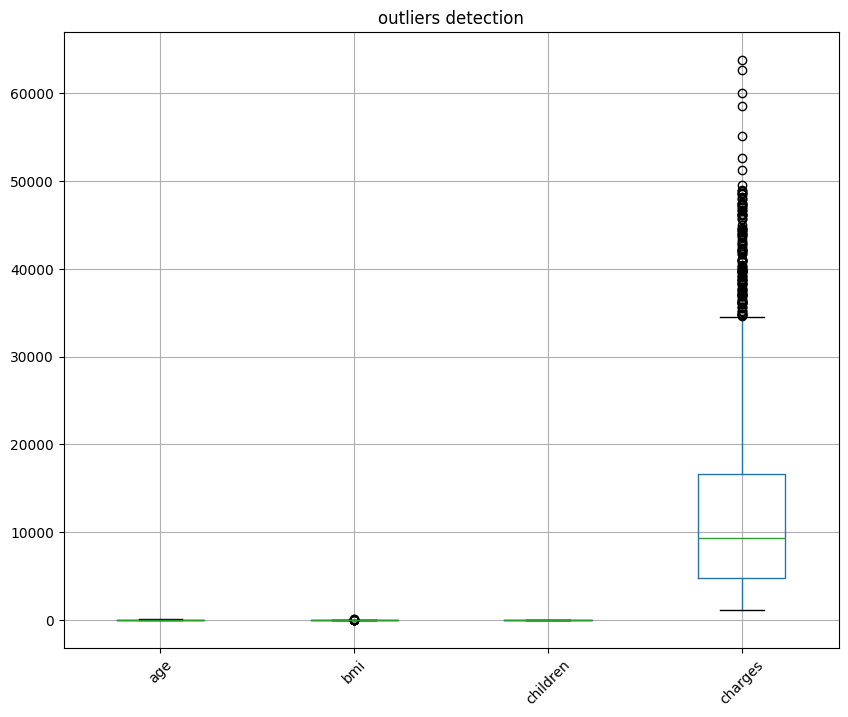

In [119]:
#OUTLIERS

#Boxplot for detecting outliers
plt.figure(figsize=(10,8))
df.select_dtypes(exclude=object).boxplot()
plt.xticks(rotation=45)
plt.title("outliers detection")
plt.show()

In [120]:
#as charges have lot of outliers checking the highest value
print(df['charges'].max())
#bmi max and min value
print(df['bmi'].max())
print(df['bmi'].min())
#as these are posible values we wont treat outliers

63770.42801
53.13
15.96


In [121]:
#ONE-HOT Encoding
df=pd.get_dummies(df,columns=['sex','smoker','region'],drop_first=True)
df

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...
1333,50,30.970,3,10600.54830,True,False,True,False,False
1334,18,31.920,0,2205.98080,False,False,False,False,False
1335,18,36.850,0,1629.83350,False,False,False,True,False
1336,21,25.800,0,2007.94500,False,False,False,False,True


In [122]:
#feature selection
corr=df.corr(numeric_only=True)
print(corr['charges'].sort_values(ascending=False))

charges             1.000000
smoker_yes          0.787234
age                 0.298308
bmi                 0.198401
region_southeast    0.073578
children            0.067389
sex_male            0.058044
region_northwest   -0.038695
region_southwest   -0.043637
Name: charges, dtype: float64


In [123]:
#input output separations
x=df.drop('charges',axis=1)
y=df['charges']

In [124]:
#train test splitting
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.30,random_state=41)
print(xtrain.shape)
print(xtest.shape)
print(ytrain.shape)

(935, 8)
(402, 8)
(935,)


In [125]:
#feature scaling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
scaler.fit(xtrain)
xtrain=scaler.transform(xtrain)
xtrain

array([[ 0.98665404, -1.13903248,  0.75509714, ..., -0.57282196,
        -0.63719309, -0.53488998],
       [ 0.3458163 ,  0.10289222, -0.07943693, ..., -0.57282196,
        -0.63719309, -0.53488998],
       [-1.43428853,  0.7859508 , -0.91397101, ...,  1.74574312,
        -0.63719309, -0.53488998],
       ...,
       [-0.93585918, -0.17654084,  2.42416529, ..., -0.57282196,
        -0.63719309, -0.53488998],
       [ 1.05785823,  0.08491699, -0.91397101, ..., -0.57282196,
         1.56938299, -0.53488998],
       [ 0.48822469, -0.80403963,  3.25869937, ..., -0.57282196,
        -0.63719309,  1.86954334]])

In [126]:
xtest=scaler.transform(xtest)
xtest

array([[ 1.62749178, -0.03682431,  0.75509714, ...,  1.74574312,
        -0.63719309, -0.53488998],
       [ 1.342675  , -0.40940172, -0.91397101, ...,  1.74574312,
        -0.63719309, -0.53488998],
       [-0.57983821,  0.02527193, -0.91397101, ..., -0.57282196,
        -0.63719309, -0.53488998],
       ...,
       [ 0.55942888,  0.42889745, -0.91397101, ..., -0.57282196,
        -0.63719309, -0.53488998],
       [-1.50549272, -1.2272745 , -0.91397101, ..., -0.57282196,
         1.56938299, -0.53488998],
       [ 1.76990016,  1.59483597, -0.91397101, ..., -0.57282196,
         1.56938299, -0.53488998]])

In [127]:
from sklearn.model_selection import GridSearchCV
#HYPERPARAMETER TUNING FOR LINEAR REGRESSION
from sklearn.linear_model import LinearRegression
lr_model=LinearRegression()
lr_param={'fit_intercept':[True,False],'positive':[True,False]}
lr_grid=GridSearchCV(lr_model,lr_param,cv=3,scoring="r2")
lr_grid.fit(xtrain,ytrain)
lr_grid.best_params_

{'fit_intercept': True, 'positive': True}

In [128]:
#LINEAR REGRESSION MODEL BUILDING
lr=LinearRegression(fit_intercept= True, positive= True)
lr.fit(xtrain,ytrain)
lr_ypred=lr.predict(xtest)
lr_ypred

array([15301.30513628, 12440.46069362,  5837.30390861,  9517.18860995,
        9065.62974341, 11312.2314373 , 29195.09844729,  6163.01630677,
        8033.55828287,  3317.46687449, 36625.69055319, 35997.76802909,
       11446.05173082, 29190.50517809,  6095.74672542, 12538.20929108,
       15908.65924523, 11711.46150951, 14463.69783674, 34639.08661704,
        5290.80992742, 30625.59013999, 12472.52205439,  8151.99860072,
       17518.29508145, 38323.5135411 ,  4872.00368261,  4274.64906603,
        9346.18033981, 15354.83665113,  6646.28864284,  4883.85709786,
        6463.75953773, 13268.76707672,  8782.84015047,  5855.72381855,
       14780.33975704,  5761.49173713,  1475.3629363 ,  4731.4641764 ,
       28831.54753267,  8960.01771172, 11705.01073335, 16360.30834365,
        1560.48068934,  5763.22387819,  7138.23159105, 36509.94467499,
        1281.37796154,  9317.69757817,   959.01072583,  6530.32948699,
       10313.21270688,  9762.51374835,  4968.47323714,  5264.95026861,
      

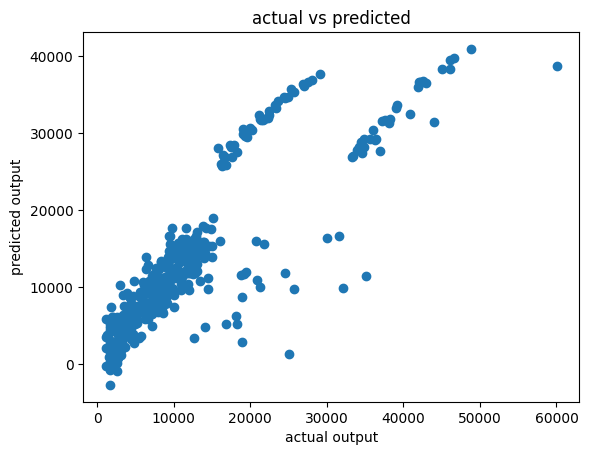

In [129]:
#REGRESSION PLOT
plt.scatter(ytest,lr_ypred,)
plt.xlabel("actual output")
plt.ylabel("predicted output")
plt.title("actual vs predicted")
plt.show()

In [130]:
#HYPERPARAMETER TUNING FOR K-NEAREST NEIGHBORS
from sklearn.neighbors import KNeighborsRegressor
knn_model=KNeighborsRegressor()
knn_param={'n_neighbors':[5,7,9,11],'weights':['uniform','random'],'metric':['euclidean','manhattan']}
knn_grid=GridSearchCV(knn_model,knn_param,cv=3,scoring="r2")
knn_grid.fit(xtrain,ytrain)
knn_grid.best_params_

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
24 fits failed out of a total of 48.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
24 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_par

{'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'uniform'}

In [131]:
#KNN MODEL BUILDING
knn=KNeighborsRegressor(metric= 'euclidean', n_neighbors= 7, weights='uniform')
knn.fit(xtrain,ytrain)
knn_ypred=knn.predict(xtest)
knn_ypred

array([13545.70937857, 14416.66388857,  4356.62681429,  7691.214     ,
        6393.32528571,  9698.42710714, 35472.99355286,  7560.70345857,
        5851.21357143,  3263.39375714, 34740.23082857, 42382.41125714,
       13773.76738714, 28271.54600429,  2140.53162857, 13047.47934143,
       13027.08478714, 11407.93550714, 14891.10859143, 20064.19435714,
        4583.08505   , 21351.03116429,  7039.47442857,  5459.97687143,
       11615.29582429, 38932.50120143,  2734.38447857,  3889.62873   ,
        6729.31117857, 15161.91576571,  8710.05525   ,  3299.95522143,
       13045.75814571, 16056.63751429,  8343.80314571,  1765.23797143,
       12764.07144286,  6016.11835714,  3863.95392143, 10604.76300143,
       36032.94116286,  4292.51928571, 16879.72368   , 12815.43150143,
        2260.225     ,  2598.35045   ,  6539.63328571, 43344.03382857,
        4732.71438571,  7781.47976714,  2319.40087143,  5898.67896429,
        7364.22625   , 12060.05792143,  5192.8956    ,  7521.38444714,
      

In [132]:
#HYPERPARAMETER TUNING FOR DECISION TREE
from sklearn.tree import DecisionTreeRegressor
dt_model=DecisionTreeRegressor()
dt_param={'criterion':['squared_error','friedman_mse','absolute_error'],'max_depth':[5,7,10,None],
          'min_samples_split':[2,5,10],'min_samples_leaf':[1,2,4]}
dt_grid=GridSearchCV(dt_model,dt_param,cv=3,scoring="r2")
dt_grid.fit(xtrain,ytrain)
dt_grid.best_params_

{'criterion': 'absolute_error',
 'max_depth': 5,
 'min_samples_leaf': 4,
 'min_samples_split': 2}

In [133]:
#DT MODEL BUILDING
dt=DecisionTreeRegressor(criterion='absolute_error',max_depth= 5,min_samples_leaf= 4,min_samples_split= 2)
dt.fit(xtrain,ytrain)
dt_ypred=dt.predict(xtest)
dt_ypred

array([15555.18875 , 11356.6609  ,  4728.896125,  6593.5083  ,
        6593.5083  ,  9283.562   , 38428.09715 ,  4728.896125,
        6593.5083  ,  2846.72225 , 29526.8003  , 44952.337975,
       11356.6609  , 34556.00155 ,  1906.35825 , 11356.6609  ,
       13464.3826  ,  9563.029   , 10600.5483  , 24358.316025,
        4728.896125, 21215.433   ,  8516.29385 ,  6593.5083  ,
       13464.3826  , 46972.39665 ,  1906.35825 ,  2846.72225 ,
        6593.5083  , 15555.18875 ,  8516.29385 ,  1906.35825 ,
        6593.5083  , 11356.6609  ,  4728.896125,  1906.35825 ,
       13464.3826  ,  4728.896125,  1906.35825 ,  4728.896125,
       34556.00155 ,  2846.72225 ,  6593.5083  , 13464.3826  ,
        1906.35825 ,  2846.72225 ,  6121.01425 , 40182.246   ,
        1906.35825 ,  6593.5083  ,  1906.35825 ,  6593.5083  ,
        6593.5083  ,  6121.01425 ,  4728.896125,  4591.135675,
        4728.896125,  6593.5083  ,  4728.896125, 12269.68865 ,
       11356.6609  ,  8516.29385 ,  8007.09805 ,  1906.

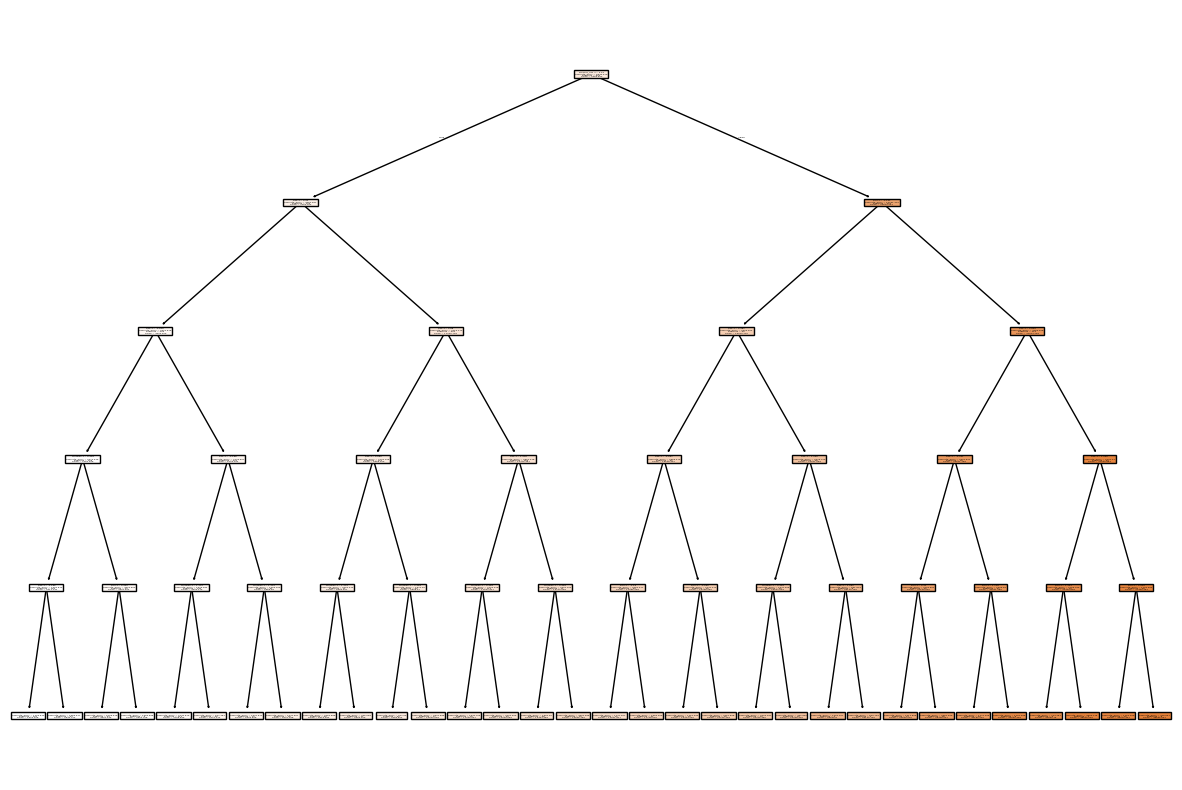

In [134]:
#TREE VISUALIZATION
from sklearn import tree
plt.figure(figsize=(15,10))
tree.plot_tree(dt,feature_names=x.columns,class_names=df.charges.astype(str).unique(),filled=True)
plt.show()

In [135]:
#HYPERPARAMETER TUNING FOR RANDOM FOREST REGRESSOR
from sklearn.ensemble import RandomForestRegressor
rfr_model=RandomForestRegressor()
rfr_param={'n_estimators':[100,200],'max_depth':[5,10,15,None],'min_samples_split':[2,5,10],'min_samples_leaf':[1,2,4]}
rfr_grid=GridSearchCV(rfr_model,rfr_param,cv=3,scoring="r2")
rfr_grid.fit(xtrain,ytrain)
rfr_grid.best_params_

{'max_depth': 5,
 'min_samples_leaf': 4,
 'min_samples_split': 10,
 'n_estimators': 200}

In [136]:
#RFR MODEL BUILDING
rfr=RandomForestRegressor(n_estimators=100,max_depth= 5,min_samples_leaf= 4,min_samples_split= 2)
rfr.fit(xtrain,ytrain)
rfr_ypred=rfr.predict(xtest)
rfr_ypred

array([16470.78866821, 12594.49649714,  4727.77559484,  7346.38882482,
        7234.41319163, 10329.93324167, 36113.30850458,  6372.78493092,
        7243.26246243,  4808.24884275, 27403.77596336, 44061.08165692,
       12573.30527766, 35403.82451198,  3399.01514628, 14526.20653772,
       14153.29392242, 11499.9268966 , 12887.67845785, 23595.66723145,
        6193.666211  , 20905.51819373,  7799.81678721,  6805.52793935,
       14327.14342709, 47502.11235562,  3381.2957553 ,  3678.06305315,
        7266.76559563, 17575.68607526, 10605.19260191,  3352.82686772,
        7560.07129715, 12791.57411027,  5511.58167467,  3551.68730754,
       14231.76108259,  6257.57974611,  2995.89226573,  6637.75309036,
       35310.12812865,  4487.24495494,  7705.90874256, 13951.0653186 ,
        3031.05999216,  3991.1625567 ,  6038.34727538, 42532.05544133,
        4737.9398289 ,  7273.33226601,  2915.9576749 ,  7714.44864062,
        7184.21699954,  6275.926769  ,  5776.56230607,  6769.30864518,
      

In [137]:
#HYPERPARAMETER TUNING FOR XGBOOST
from xgboost import XGBRegressor
xgb_model=XGBRegressor()
xgb_param={'n_estimators':[100,200],'max_depth':[5,10,15,None],'learning_rate':[0.01,0.1],'subsample':[0.8,1.0]}
xgb_grid=GridSearchCV(xgb_model,xgb_param,cv=3,scoring="r2")
xgb_grid.fit(xtrain,ytrain)
xgb_grid.best_params_

{'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}

In [138]:
#XGB MODEL BUILDING
xgb=XGBRegressor(learning_rate=0.01, max_depth=5,n_estimators= 200,subsample=0.8)
xgb.fit(xtrain,ytrain)
xgb_ypred=xgb.predict(xtest)
xgb_ypred

array([16149.133 , 12511.173 ,  6036.67  ,  7953.4565,  8304.34  ,
       11123.063 , 32940.125 ,  7037.2686,  8174.6973,  6680.4995,
       25181.752 , 39110.188 , 12686.913 , 32485.164 ,  4492.512 ,
       15287.812 , 14258.245 , 11489.249 , 14423.08  , 22734.977 ,
        6896.179 , 20102.492 ,  8811.849 ,  7451.552 , 13839.0205,
       41621.816 ,  4880.1655,  5154.8027,  8368.559 , 17240.715 ,
       10560.431 ,  4430.4717,  8238.834 , 12642.79  ,  6182.844 ,
        4628.941 , 14294.823 ,  6899.99  ,  4181.1323,  8006.5347,
       32859.73  ,  5990.2856,  8919.0625, 13722.116 ,  4668.656 ,
        5423.9653,  7438.114 , 38967.793 ,  5692.2905,  8350.694 ,
        4002.441 ,  8550.256 ,  7990.9873,  7665.4473,  6767.141 ,
        7801.583 ,  7612.1206,  8449.666 ,  7943.9116, 14692.502 ,
       12502.155 , 10670.053 ,  8417.505 ,  4377.078 ,  6851.4663,
       10276.018 ,  8862.009 ,  7479.2935, 19307.225 , 13330.495 ,
       19572.527 , 15161.074 ,  8199.251 ,  4890.663 , 13661.0

In [139]:
#TRAINING AND TESTING SCORE
print("LR training score:",lr.score(xtrain,ytrain),"testing score:",lr.score(xtest,ytest))
print("KNN training score:",knn.score(xtrain,ytrain),"testing score:",knn.score(xtest,ytest))
print("DT training score:",dt.score(xtrain,ytrain),"testing score:",dt.score(xtest,ytest))
print("RFR training score:",rfr.score(xtrain,ytrain),"testing score:",rfr.score(xtest,ytest))
print("XGB training score:",xgb.score(xtrain,ytrain),"testing score:",xgb.score(xtest,ytest))

LR training score: 0.75174714201566 testing score: 0.7334220639298767
KNN training score: 0.8456279104920021 testing score: 0.7740084769437738
DT training score: 0.8564134035136097 testing score: 0.8603537317759736
RFR training score: 0.8862815380043549 testing score: 0.8616509959225405
XGB training score: 0.8770493101399607 testing score: 0.8462089702835216


In [141]:
#PERFORMANCE EVALUATION
from sklearn.metrics import mean_squared_error,mean_absolute_error,root_mean_squared_error,r2_score

In [142]:
#MEAN SQUARED ERROR
print("LR:",mean_squared_error(ytest,lr_ypred))
print("KNN:",mean_squared_error(ytest,knn_ypred))
print("DT:",mean_squared_error(ytest,dt_ypred))
print("RFR:",mean_squared_error(ytest,rfr_ypred))
print("XGB:",mean_squared_error(ytest,xgb_ypred))

LR: 30030468.975057293
KNN: 25458338.832590863
DT: 15731395.430569379
RFR: 15585256.364147613
XGB: 17324827.45806819


In [143]:
#ROOT MEAN SQUARED ERROR
print("LR:",root_mean_squared_error(ytest,lr_ypred))
print("KNN:",root_mean_squared_error(ytest,knn_ypred))
print("DT:",root_mean_squared_error(ytest,dt_ypred))
print("RFR:",root_mean_squared_error(ytest,rfr_ypred))
print("XGB:",root_mean_squared_error(ytest,xgb_ypred))

LR: 5480.00629334103
KNN: 5045.62571269321
DT: 3966.282318566012
RFR: 3947.816657868956
XGB: 4162.310351003177


In [144]:
#MEAN ABSOLUTE ERROR
print("LR:",mean_absolute_error(ytest,lr_ypred))
print("KNN:",mean_absolute_error(ytest,knn_ypred))
print("DT:",mean_absolute_error(ytest,dt_ypred))
print("RFR:",mean_absolute_error(ytest,rfr_ypred))
print("XGB:",mean_absolute_error(ytest,xgb_ypred))

LR: 3884.937821324769
KNN: 3214.275012109097
DT: 1670.7999431218907
RFR: 2272.1037805969054
XGB: 2860.760706559585


In [145]:
#R2 SCORE
print("LR:",r2_score(ytest,lr_ypred))
print("KNN:",r2_score(ytest,knn_ypred))
print("DT:",r2_score(ytest,dt_ypred))
print("RFR:",r2_score(ytest,rfr_ypred))
print("XGB:",r2_score(ytest,xgb_ypred))

LR: 0.7334220639298767
KNN: 0.7740084769437738
DT: 0.8603537317759736
RFR: 0.8616509959225405
XGB: 0.8462089702835216
